In [25]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [26]:
df = pd.read_parquet(r'..\data\processed\options_filtered.parquet')

In [27]:
df.shape

(3391881, 27)

In [28]:
df.columns

Index(['quote_unixtime', 'quote_readtime', 'quote_date', 'quote_time_hours',
       'underlying_last', 'expire_date', 'expire_unix', 'dte', 'delta',
       'gamma', 'vega', 'theta', 'rho', 'iv', 'volume', 'last', 'bid', 'ask',
       'strike', 'strike_distance', 'strike_distance_pct', 'size_bid',
       'size_ask', 'type', 'mid', 'spread', 'relative_spread'],
      dtype='str')

In [29]:
df_call = df[df['type'] == 'call']
df_put = df[df['type'] == 'put']

In [30]:
df_call.shape

(1634377, 27)

In [31]:
data = pd.merge(df_call, df_put, on = ['quote_unixtime', 'quote_readtime', 'quote_date', 'quote_time_hours',
       'underlying_last', 'expire_date', 'expire_unix', 'dte', 'strike', 'strike_distance', 'strike_distance_pct' ], suffixes = ['_c', '_p'])

In [32]:
data.shape

(1082530, 43)

In [33]:
data.isnull().sum()

quote_unixtime         0
quote_readtime         0
quote_date             0
quote_time_hours       0
underlying_last        0
expire_date            0
expire_unix            0
dte                    0
delta_c                0
gamma_c                0
vega_c                 0
theta_c                0
rho_c                  0
iv_c                   0
volume_c               0
last_c                 0
bid_c                  0
ask_c                  0
strike                 0
strike_distance        0
strike_distance_pct    0
size_bid_c             0
size_ask_c             0
type_c                 0
mid_c                  0
spread_c               0
relative_spread_c      0
delta_p                0
gamma_p                0
vega_p                 0
theta_p                0
rho_p                  0
iv_p                   0
volume_p               0
last_p                 0
bid_p                  0
ask_p                  0
size_bid_p             0
size_ask_p             0
type_p                 0


In [34]:
data['diff'] = data['mid_c'] - data['mid_p']

In [35]:
ratio = data['strike']/data['underlying_last']
filt = ((ratio <= 1.05) & (ratio >= 0.95))
ivs = data[filt]['iv_c'] - data[filt]['iv_p'] 

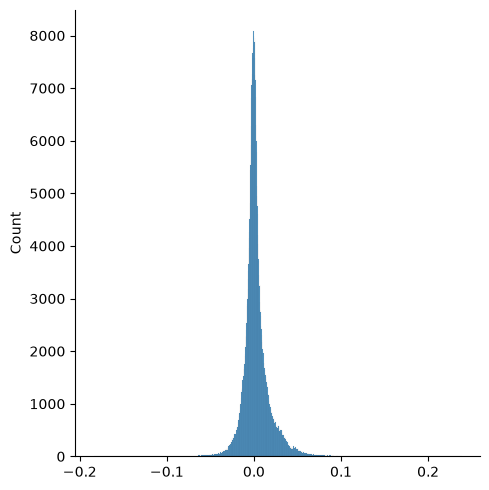

In [36]:
sns.displot(ivs)

<Axes: >

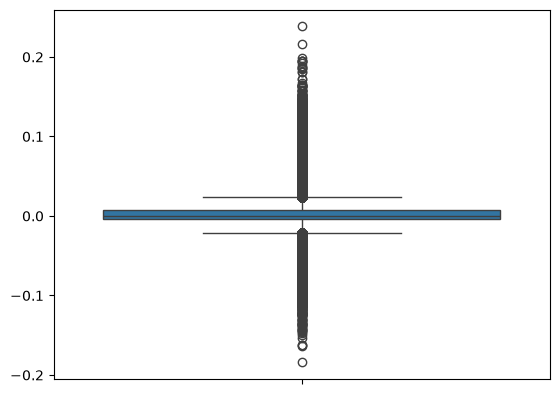

In [37]:
sns.boxplot(ivs)

In [38]:
ivs.describe()

count    428798.000000
mean          0.002638
std           0.015954
min          -0.184070
25%          -0.004330
50%           0.000530
75%           0.007080
max           0.238490
dtype: float64

In [39]:
data.columns

Index(['quote_unixtime', 'quote_readtime', 'quote_date', 'quote_time_hours',
       'underlying_last', 'expire_date', 'expire_unix', 'dte', 'delta_c',
       'gamma_c', 'vega_c', 'theta_c', 'rho_c', 'iv_c', 'volume_c', 'last_c',
       'bid_c', 'ask_c', 'strike', 'strike_distance', 'strike_distance_pct',
       'size_bid_c', 'size_ask_c', 'type_c', 'mid_c', 'spread_c',
       'relative_spread_c', 'delta_p', 'gamma_p', 'vega_p', 'theta_p', 'rho_p',
       'iv_p', 'volume_p', 'last_p', 'bid_p', 'ask_p', 'size_bid_p',
       'size_ask_p', 'type_p', 'mid_p', 'spread_p', 'relative_spread_p',
       'diff'],
      dtype='str')

In [40]:
time_filt = (data['quote_date'].dt.year == 2022)
ivs_2022 = data[filt & time_filt]['iv_c'] - data[filt & time_filt]['iv_p'] 

In [41]:
ivs_2022

75901     0.00856
75902     0.00667
75903     0.00766
75904     0.00680
75905     0.00410
           ...   
651849    0.03160
651850    0.02700
651857    0.05730
651858    0.05025
651859    0.04542
Length: 114206, dtype: float64

In [42]:
ivs_2022.describe()

count    114206.000000
mean          0.000160
std           0.017077
min          -0.104420
25%          -0.008770
50%          -0.001630
75%           0.006100
max           0.199030
dtype: float64

In [43]:
data['year'] = data['quote_date'].dt.year

In [44]:
data['year'].value_counts()

year
2021    479866
2020    429461
2022    173203
Name: count, dtype: int64

In [45]:
data['iv_gap'] = data['iv_c'] - data['iv_p']

In [46]:
year_data = data[filt].groupby(by = 'year')['iv_gap'].describe()
year_data

,count,mean,std,min,25%,50%,75%,max
year,,,,,,,,
2020,133510.0,0.006696,0.019603,-0.18407,-0.00360,0.00274,0.01552,0.23849
2021,181082.0,0.001210,0.010836,-0.11472,-0.00285,0.00048,0.00427,0.19437
2022,114206.0,0.000160,0.017077,-0.10442,-0.00877,-0.00163,0.00610,0.19903


In [49]:
data[filt].shape

(428798, 46)

In [50]:
new_data = data[filt]

In [51]:
new_data['diff']

1          20.775
2          17.740
3          16.735
4          14.740
5          11.740
            ...  
1082469   -15.510
1082470   -20.580
1082510     7.120
1082511    -3.000
1082512   -11.750
Name: diff, Length: 428798, dtype: float64

In [52]:
new_data.columns

Index(['quote_unixtime', 'quote_readtime', 'quote_date', 'quote_time_hours',
       'underlying_last', 'expire_date', 'expire_unix', 'dte', 'delta_c',
       'gamma_c', 'vega_c', 'theta_c', 'rho_c', 'iv_c', 'volume_c', 'last_c',
       'bid_c', 'ask_c', 'strike', 'strike_distance', 'strike_distance_pct',
       'size_bid_c', 'size_ask_c', 'type_c', 'mid_c', 'spread_c',
       'relative_spread_c', 'delta_p', 'gamma_p', 'vega_p', 'theta_p', 'rho_p',
       'iv_p', 'volume_p', 'last_p', 'bid_p', 'ask_p', 'size_bid_p',
       'size_ask_p', 'type_p', 'mid_p', 'spread_p', 'relative_spread_p',
       'diff', 'year', 'iv_gap'],
      dtype='str')

In [64]:
# --- Step B: fit the put-call parity line for each (date, expiry) ---

def fit_forward(g):
    """g = all near-the-money call/put pairs for ONE quote_date + expire_date."""
    n = len(g)
    if n < 3:                                   # too few points to fit a reliable line
        return pd.Series({'F': np.nan, 'D': np.nan, 'n_pairs': n})
    slope, intercept = np.polyfit(g['strike'], g['diff'], 1)   # fit: diff = slope*K + intercept
    D = -slope                                  # parity: C - P = D*F - D*K  → slope = -D
    F = intercept / D                           #                           → intercept = D*F
    return pd.Series({'F': F, 'D': D, 'n_pairs': n})

near = data[filt]                               # only strikes within ±5% of spot

fwd = (near
       .groupby(['quote_date', 'expire_date', 'underlying_last', 'dte'])
       .apply(fit_forward)
       .reset_index())

fwd['T'] = fwd['dte'] / 365
fwd['F_over_S'] = fwd['F'] / fwd['underlying_last']
fwd

,quote_date,expire_date,underlying_last,dte,F,D,n_pairs,T,F_over_S
0,2020-01-02,2020-01-10,324.87,8.00,324.718130,1.006743,4.0,0.021918,0.999533
1,2020-01-02,2020-01-13,324.87,11.00,324.770379,0.999712,17.0,0.030137,0.999693
2,2020-01-02,2020-01-15,324.87,13.00,324.805820,0.999411,19.0,0.035616,0.999802
3,2020-01-02,2020-01-17,324.87,15.00,324.826237,1.006801,10.0,0.041096,0.999865
4,2020-01-02,2020-01-21,324.87,19.00,324.914632,0.999434,13.0,0.052055,1.000137
...,...,...,...,...,...,...,...,...,...
23064,2022-12-30,2024-01-19,382.44,385.00,394.161020,1.025650,5.0,1.054795,1.030648
23065,2022-12-30,2024-06-21,382.44,538.96,398.669817,0.979707,5.0,1.476603,1.042438
23066,2022-12-30,2024-12-20,382.44,721.00,405.673753,0.940769,3.0,1.975342,1.060751
23067,2022-12-30,2025-01-17,382.44,749.00,404.175201,0.916308,3.0,2.052055,1.056833


In [65]:
# --- Step C: sanity checks on the forwards ---

# 1. How many groups, how many failed?
print(fwd.shape)
print('failed groups (<3 pairs):', fwd['F'].isna().sum())

(23069, 9)
failed groups (<3 pairs): 1171


In [66]:
# 2. F/S table by year and maturity
fwd['year'] = fwd['quote_date'].dt.year
fwd['T_bucket'] = pd.cut(fwd['T'], [0, 0.1, 0.25, 0.5, 1, 3.1],
                         labels=['<1m', '1-3m', '3-6m', '6-12m', '1-3y'])

fwd.pivot_table(index='year', columns='T_bucket', values='F_over_S',
                aggfunc='median', observed=True).round(4)

T_bucket,<1m,1-3m,3-6m,6-12m,1-3y
year,,,,,
2020,1.0000,0.9979,0.9953,0.9924,0.9846
2021,1.0000,0.9980,0.9963,0.9935,0.9881
2022,1.0002,1.0002,1.0020,1.0058,1.0238


In [67]:
# 3. Look at D: it should be just below 1, but isn't
print(fwd['D'].describe())
print('share of groups with D > 1:', (fwd['D'] > 1).mean().round(3))

count    21898.000000
mean         1.002633
std          0.016477
min          0.560000
25%          0.999130
50%          1.002100
75%          1.007583
max          1.243500
Name: D, dtype: float64
share of groups with D > 1: 0.641


In [68]:
# 4. Which groups and rows have no forward?
all_groups = df[['quote_date', 'expire_date']].drop_duplicates()
print('groups in data:', len(all_groups))
print('groups in fwd :', len(fwd))
print('groups with no near-the-money pair at all:', len(all_groups) - len(fwd))

good = fwd.loc[fwd['F'].notna(), ['quote_date', 'expire_date', 'F']]
check = df.merge(good, on=['quote_date', 'expire_date'], how='left')
print('rows without F:', check['F'].isna().sum(),
      'share:', round(check['F'].isna().mean(), 4))
print(check.loc[check['F'].isna(), 'dte'].describe().round(1))

groups in data: 23534
groups in fwd : 23069
groups with no near-the-money pair at all: 465
rows without F: 72166 share: 0.0213
count    72166.0
mean       383.7
std        303.4
min          7.0
25%         34.0
50%        395.0
75%        625.0
max       1096.0
Name: dte, dtype: float64


In [69]:
# --- Step D: attach F, drop rows without one, build features ---
good = fwd.loc[fwd['F'].notna(), ['quote_date', 'expire_date', 'F']]
feat = df.merge(good, on=['quote_date', 'expire_date'], how='inner')   # inner = drop rows with no F
print('rows dropped for missing F:', len(df) - len(feat))

feat['T'] = feat['dte'] / 365
feat['k'] = np.log(feat['strike'] / feat['F'])
feat['w'] = feat['iv'] ** 2 * feat['T']

rows dropped for missing F: 72166


In [70]:
# --- Step E: keep out-of-the-money options, and a sensible k range ---
otm = ((feat['type'] == 'put')  & (feat['k'] <  0)) | \
      ((feat['type'] == 'call') & (feat['k'] >= 0))
feat = feat[otm]
feat = feat[feat['k'].abs() <= 1].reset_index(drop=True)

print(feat.shape, 'days:', feat['quote_date'].nunique())
print(feat['type'].value_counts())
print('duplicate (date, expiry, strike):',
      feat.duplicated(['quote_date', 'expire_date', 'strike']).sum())

(2017522, 31) days: 749
type
put     1252837
call     764685
Name: count, dtype: int64
duplicate (date, expiry, strike): 0


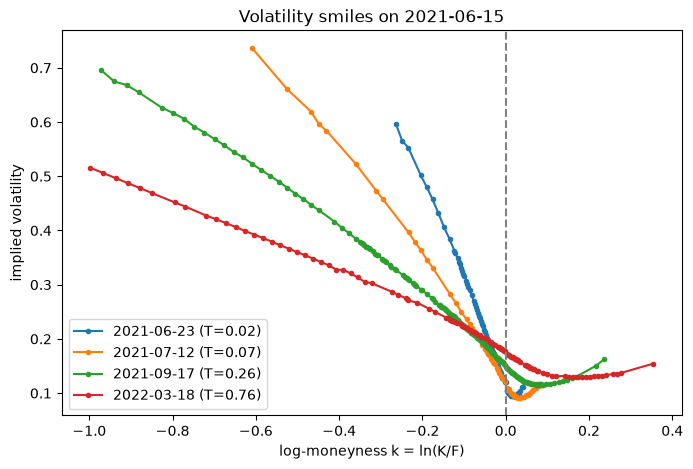

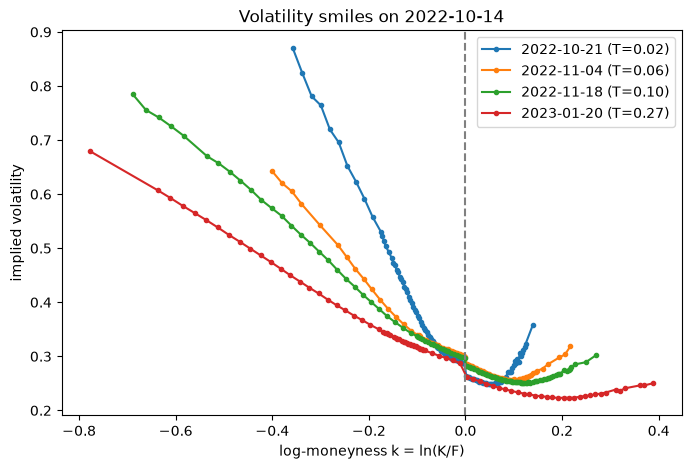

In [71]:
# --- Step F: plot smiles for one day ---
def plot_smile(data, date, n_expiries=4):
    day = data[data['quote_date'] == date]
    expiries = sorted(day['expire_date'].unique())
    picks = expiries[::max(1, len(expiries) // n_expiries)][:n_expiries]   # spread-out expiries
    fig, ax = plt.subplots(figsize=(8, 5))
    for e in picks:
        s = day[day['expire_date'] == e].sort_values('k')
        ax.plot(s['k'], s['iv'], marker='.',
                label=f"{pd.Timestamp(e).date()} (T={s['T'].iloc[0]:.2f})")
    ax.axvline(0, color='grey', linestyle='--')
    ax.set_xlabel('log-moneyness k = ln(K/F)')
    ax.set_ylabel('implied volatility')
    ax.set_title(f'Volatility smiles on {pd.Timestamp(date).date()}')
    ax.legend()
    plt.show()

plot_smile(feat, '2021-06-15')
plot_smile(feat, '2022-10-14')

In [72]:
# --- Save ---
feat.to_parquet(r'..\data\processed\options_features.parquet')

Why is there a step at k = 0 in late 2022, and what does that say about the American-IV assumption?